Connected to Python 3.14.7

In [ ]:
import numpy as np
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import pingouin as pg
from scipy import stats

In [ ]:
iris = load_iris()
iris_pd = pd.DataFrame(data=iris.data, columns=iris.feature_names)


In [ ]:
display(iris_pd.head())
display(iris_pd.info())
display(iris_pd.describe())
display(iris_pd.shape)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


None

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


(150, 4)

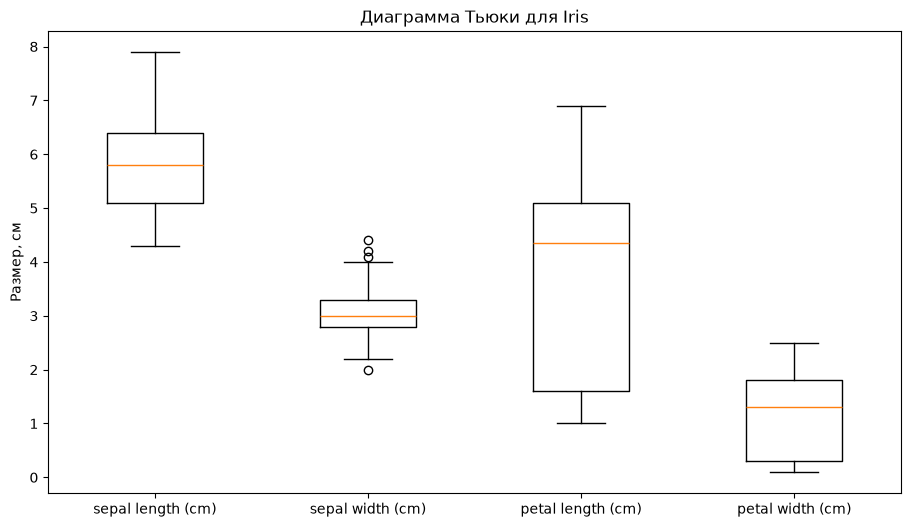

In [ ]:
plt.figure(figsize=(11, 6))

plt.boxplot(iris_pd.to_numpy(),tick_labels=iris_pd.columns)

plt.title("Диаграмма Тьюки для Iris")
plt.ylabel("Размер, см")
plt.show()

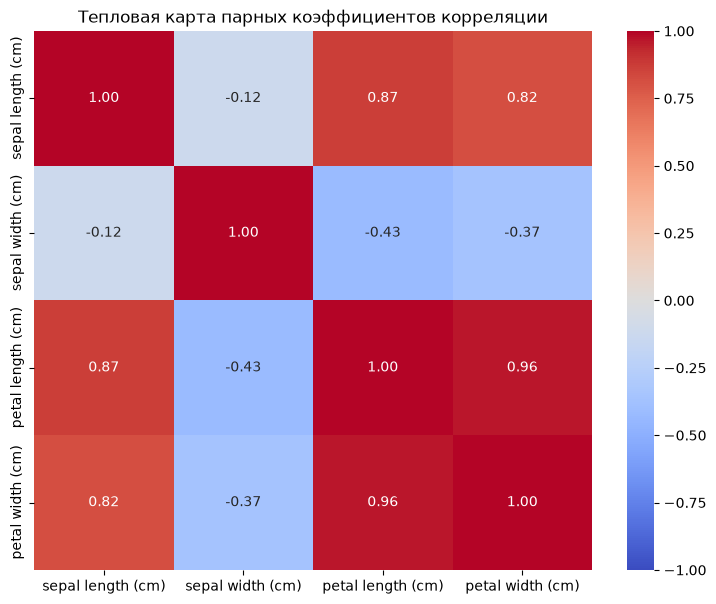

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


In [ ]:
import seaborn as sns 
corr_matrix = iris_pd.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot = True,fmt=".2f",cmap="coolwarm",  vmin=-1, vmax=1)
plt.title("Тепловая карта парных коэффициентов корреляции")
plt.show()
display(corr_matrix)

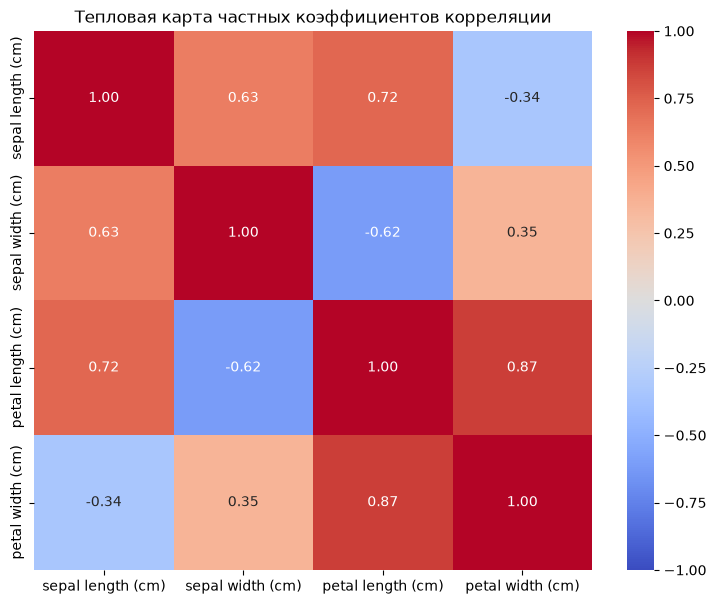

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,0.628571,0.719066,-0.339617
sepal width (cm),0.628571,1.000000,-0.615292,0.352626
petal length (cm),0.719066,-0.615292,1.000000,0.870770
petal width (cm),-0.339617,0.352626,0.870770,1.000000


In [ ]:
partial_corr_matrix = iris_pd.pcorr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot = True,fmt=".2f",cmap="coolwarm",  vmin=-1, vmax=1, center = 0)
plt.title("Тепловая карта частных коэффициентов корреляции")
plt.show()
display(partial_corr_matrix)

In [ ]:
difference = partial_corr_matrix - corr_matrix

print("Разница между частными и парными корреляциями:")
display(difference.round(3))

Разница между частными и парными корреляциями:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),0.0,0.0,0.0,0.0
sepal width (cm),0.0,0.0,0.0,0.0
petal length (cm),0.0,0.0,0.0,0.0
petal width (cm),0.0,0.0,0.0,0.0


In [ ]:
print("Тест Колмогорова-Смирнова. Уровень значимости α = 0.05")

for col in iris_pd.columns:
    x = iris_pd[col]

    x_mean = np.mean(x)
    std = np.std(x, ddof=1)

    x_std = (x - x_mean) / std

    statistic, pvalue = stats.kstest(
        x_std, "norm", alternative="two-sided"
    )

    if pvalue > 0.05:
        result = "H0 не отвергается"
    else:
        result = "H0 отвергается"

    print(f"\nПризнак: {col}")
    print(f"Статистика D: {statistic:.4f}")
    print(f"p-value: {pvalue:.4f}")
    print(f"Вывод: {result}")

Тест Колмогорова-Смирнова. Уровень значимости α = 0.05

Признак: sepal length (cm)
Статистика D: 0.0887
p-value: 0.1781
Вывод: H0 не отвергается

Признак: sepal width (cm)
Статистика D: 0.1057
p-value: 0.0652
Вывод: H0 не отвергается

Признак: petal length (cm)
Статистика D: 0.1982
p-value: 0.0000
Вывод: H0 отвергается

Признак: petal width (cm)
Статистика D: 0.1728
p-value: 0.0002
Вывод: H0 отвергается


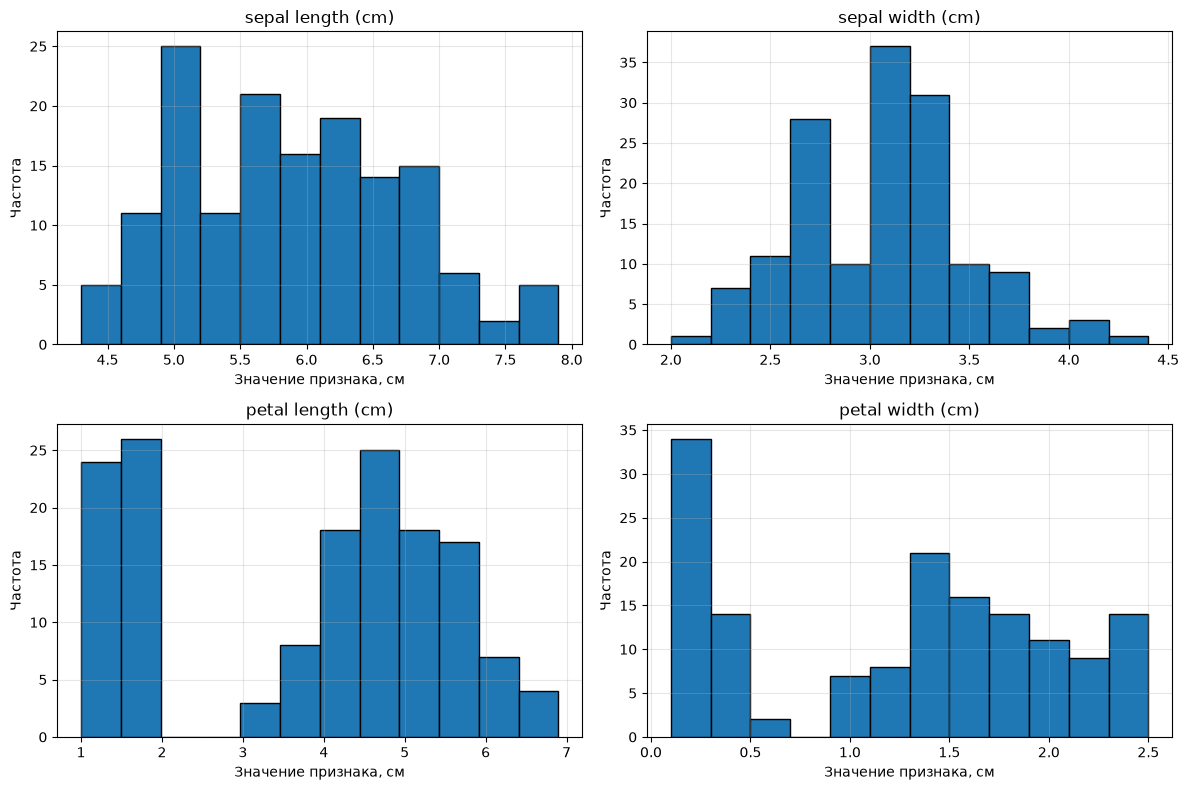

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), iris_pd.columns):
    ax.hist(
        iris_pd[col],
        bins=12,
        edgecolor="black"
    )

    ax.set_title(col)
    ax.set_xlabel("Значение признака, см")
    ax.set_ylabel("Частота")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
variation = pd.DataFrame({
    "Среднее": iris_pd.mean(),
    "СКО": iris_pd.std(),
    "Коэффициент вариации (%)":
        iris_pd.std() / iris_pd.mean().abs() * 100
})

display(variation.round(3))

,Среднее,СКО,Коэффициент вариации (%)
sepal length (cm),5.843,0.828,14.171
sepal width (cm),3.057,0.436,14.256
petal length (cm),3.758,1.765,46.974
petal width (cm),1.199,0.762,63.555
